# Tugas Clustering Lanjutan (Palmer Penguins)

## 1. Import Library dan Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
url = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(url)

### Struktur Data

In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
df.shape

(344, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Eksplorasi dan Pembersihan Data

### Nilai Kosong per Kolom

In [6]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

### Menghapus Baris dengan Nilai Kosong

In [7]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

df = df.dropna(subset=num_cols + ["species"])

### Jumlah Data Sebelum dan Sesudah Pembersihan

In [8]:
n_before = 344
print(f"Sebelum pembersihan : {n_before} baris")
print(f"Sesudah pembersihan : {len(df)} baris (dihapus {n_before - len(df)})")
print()
print(df['species'].value_counts())

Sebelum pembersihan : 344 baris
Sesudah pembersihan : 342 baris (dihapus 2)

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


### Statistik Deskriptif

In [9]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029240
std,5.459584,1.974793,14.061714,801.954536,0.817168
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [10]:
df.shape

(342, 8)

### Scatter Plot Awal

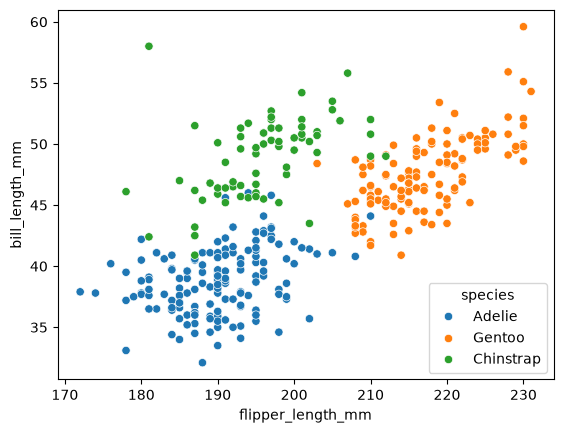

In [11]:
sns.scatterplot(data=df, x='flipper_length_mm', y='bill_length_mm', hue='species')
plt.show()

## 3. Standardisasi Data

### Memisahkan Fitur dan Label

In [12]:
X = df[num_cols]
y = df['species']

### Standardisasi (z-score)

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Cek Hasil Standardisasi

In [14]:
print(pd.DataFrame(X_scaled, columns=num_cols).describe().loc[['mean', 'std']].round(3))

      bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
mean           0.000          0.000             -0.000        0.000
std            1.001          1.001              1.001        1.001


## 4. Penerapan Algoritma

### Agglomerative Clustering

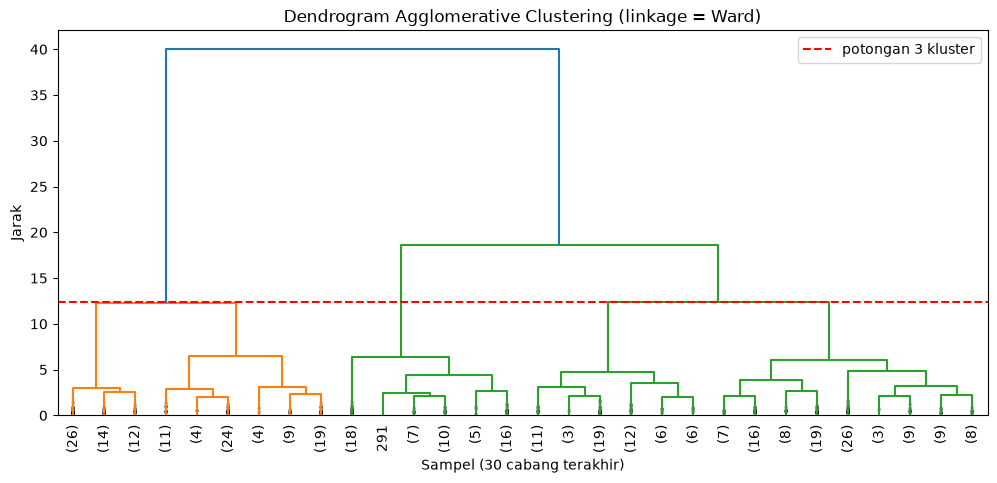

Linkage: ward | ukuran kluster: [162 123  57]


In [15]:
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score

K = 3
SEED = 42

Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_contracted=True)
plt.axhline(y=Z[-K, 2] - 1e-9, color='r', linestyle='--', label='potongan 3 kluster')
plt.title('Dendrogram Agglomerative Clustering (linkage = Ward)')
plt.xlabel('Sampel (30 cabang terakhir)')
plt.ylabel('Jarak')
plt.legend()
plt.show()

agg = AgglomerativeClustering(n_clusters=K, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)
print('Linkage: ward | ukuran kluster:', np.bincount(labels_agg))

### DBSCAN

In [16]:
rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    rows.append({'eps': eps,
                 'jumlah_kluster': len(set(lab)) - (1 if -1 in lab else 0),
                 'jumlah_noise': int((lab == -1).sum())})
dbscan_scan = pd.DataFrame(rows)
dbscan_scan

,eps,jumlah_kluster,jumlah_noise
0,0.3,4,317
1,0.4,10,171
2,0.5,4,69
3,0.6,2,33
4,0.7,2,16
5,0.8,2,5
6,1.0,2,1
7,1.2,2,1


In [17]:
cand = dbscan_scan.assign(selisih=(dbscan_scan['jumlah_kluster'] - K).abs())
best = cand.sort_values(['selisih', 'jumlah_noise']).iloc[0]
EPS = float(best['eps'])
print('eps terpilih:', EPS)
dbscan = DBSCAN(eps=EPS, min_samples=5)
labels_db = dbscan.fit_predict(X_scaled)
print('kluster:', sorted(set(labels_db) - {-1}), '| noise:', int((labels_db == -1).sum()))

# DBSCAN dengan nilai awal eps = 0.5 (sebagai pembanding)
EPS0 = 0.5
labels_db0 = DBSCAN(eps=EPS0, min_samples=5).fit_predict(X_scaled)
print(f'eps {EPS0}: kluster', sorted(set(labels_db0) - {-1}), '| noise:', int((labels_db0 == -1).sum()))

eps terpilih: 1.0
kluster: [np.int64(0), np.int64(1)] | noise: 1
eps 0.5: kluster [np.int64(0), np.int64(1), np.int64(2), np.int64(3)] | noise: 69


### Gaussian Mixture Models (3 komponen)

In [18]:
gmm = GaussianMixture(n_components=K, random_state=SEED)
labels_gmm = gmm.fit_predict(X_scaled)
print('ukuran kluster:', np.bincount(labels_gmm))

ukuran kluster: [ 67 123 152]


### Spectral Clustering (3 kluster)

In [19]:
spec = SpectralClustering(n_clusters=K, affinity='rbf', gamma=8.0,
                          random_state=SEED)
labels_spec = spec.fit_predict(X_scaled)
print('ukuran kluster:', np.bincount(labels_spec))

ukuran kluster: [160  59 123]


### Visualisasi Hasil Clustering

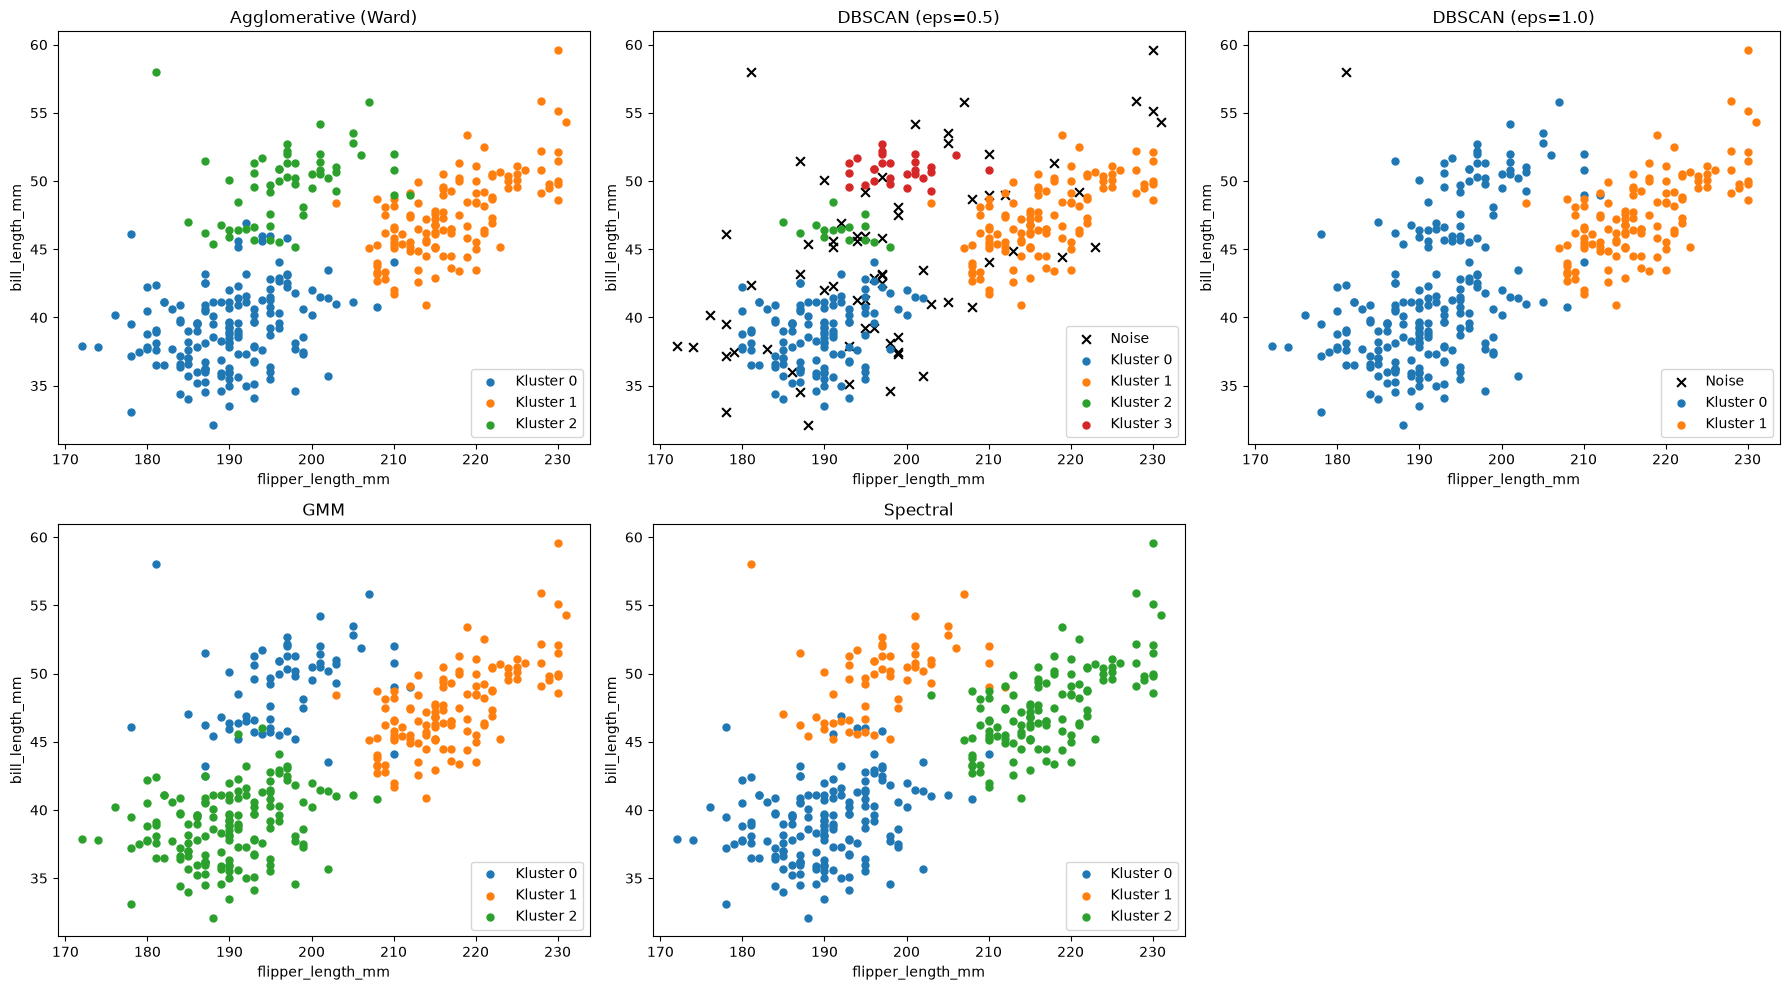

In [20]:
results = {
    'Agglomerative (Ward)': labels_agg,
    f'DBSCAN (eps={EPS0})': labels_db0,
    f'DBSCAN (eps={EPS})': labels_db,
    'GMM': labels_gmm,
    'Spectral': labels_spec,
}
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, lab) in zip(axes.ravel(), results.items()):
    for c in sorted(set(lab)):
        m = lab == c
        if c == -1:
            ax.scatter(df.loc[m, 'flipper_length_mm'], df.loc[m, 'bill_length_mm'],
                       c='black', marker='x', s=40, label='Noise')
        else:
            ax.scatter(df.loc[m, 'flipper_length_mm'], df.loc[m, 'bill_length_mm'],
                       s=25, label=f'Kluster {c}')
    ax.set_title(name)
    ax.set_xlabel('flipper_length_mm')
    ax.set_ylabel('bill_length_mm')
    ax.legend()
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

## 5. Evaluasi Hasil Clustering

### Silhouette Score, Rand Index, dan NMI

In [21]:
def sil(X, lab):
    mask = lab != -1
    if len(set(lab[mask])) < 2:
        return np.nan, int((~mask).sum())
    return silhouette_score(X[mask], lab[mask]), int((~mask).sum())

eval_rows = []
for name, lab in results.items():
    s, dropped = sil(X_scaled, lab)
    eval_rows.append({'Algoritma': name,
                    'Silhouette': s,
                    'Titik dibuang': dropped,
                    'Rand Index': rand_score(y, lab),
                    'NMI': normalized_mutual_info_score(y, lab)})
eval_df = pd.DataFrame(eval_rows).set_index('Algoritma')
eval_df.round(4)

,Silhouette,Titik dibuang,Rand Index,NMI
Algoritma,,,,
Agglomerative (Ward),0.4541,0,0.9608,0.9007
DBSCAN (eps=0.5),0.4235,69,0.8525,0.6631
DBSCAN (eps=1.0),0.5336,1,0.8254,0.7627
GMM,0.4545,0,0.9817,0.9349
Spectral,0.4546,0,0.9676,0.9138


### Uji Kestabilan

In [22]:
def make_models():
    return {
        'Agglomerative (Ward)': lambda: AgglomerativeClustering(n_clusters=K, linkage='ward'),
        f'DBSCAN (eps={EPS0})': lambda: DBSCAN(eps=EPS0, min_samples=5),
        f'DBSCAN (eps={EPS})': lambda: DBSCAN(eps=EPS, min_samples=5),
        'GMM': lambda: GaussianMixture(n_components=K, random_state=SEED),
        'Spectral': lambda: SpectralClustering(n_clusters=K, affinity='rbf', gamma=8.0, random_state=SEED),
    }

n = len(X_scaled)
stab_rows = []
for run in range(3):
    rng = np.random.RandomState(run)
    idx = rng.choice(n, size=int(0.9 * n), replace=False)
    for name, mk in make_models().items():
        lab_sub = mk().fit_predict(X_scaled[idx])
        full = results[name][idx]
        stab_rows.append({'Algoritma': name, 'Run': run + 1, 'Rand Index': rand_score(full, lab_sub), 'NMI': normalized_mutual_info_score(full, lab_sub)})
stab_df = pd.DataFrame(stab_rows)
stab_df.pivot(index='Algoritma', columns='Run', values=['Rand Index', 'NMI']).round(4)

Rand Index                     NMI                
Run                           1       2       3       1       2       3
Algoritma                                                              
Agglomerative (Ward)     1.0000  0.9796  0.9759  1.0000  0.9388  0.9303
DBSCAN (eps=0.5)         0.9888  0.9750  0.9722  0.9517  0.9247  0.9274
DBSCAN (eps=1.0)         1.0000  0.9977  1.0000  1.0000  0.9830  1.0000
GMM                      0.9958  0.7616  1.0000  0.9827  0.6710  1.0000
Spectral                 0.9958  1.0000  1.0000  0.9825  1.0000  1.0000

### Tabel Perbandingan

In [23]:
stab_mean = stab_df.groupby('Algoritma')[['Rand Index', 'NMI']].mean()
stab_mean.columns = ['Stabilitas RI (rata-rata)', 'Stabilitas NMI (rata-rata)']
summary = eval_df.join(stab_mean)
summary.round(4)

,Silhouette,Titik dibuang,Rand Index,NMI,Stabilitas RI (rata-rata),Stabilitas NMI (rata-rata)
Algoritma,,,,,,
Agglomerative (Ward),0.4541,0,0.9608,0.9007,0.9851,0.9563
DBSCAN (eps=0.5),0.4235,69,0.8525,0.6631,0.9787,0.9346
DBSCAN (eps=1.0),0.5336,1,0.8254,0.7627,0.9992,0.9943
GMM,0.4545,0,0.9817,0.9349,0.9192,0.8846
Spectral,0.4546,0,0.9676,0.9138,0.9986,0.9942


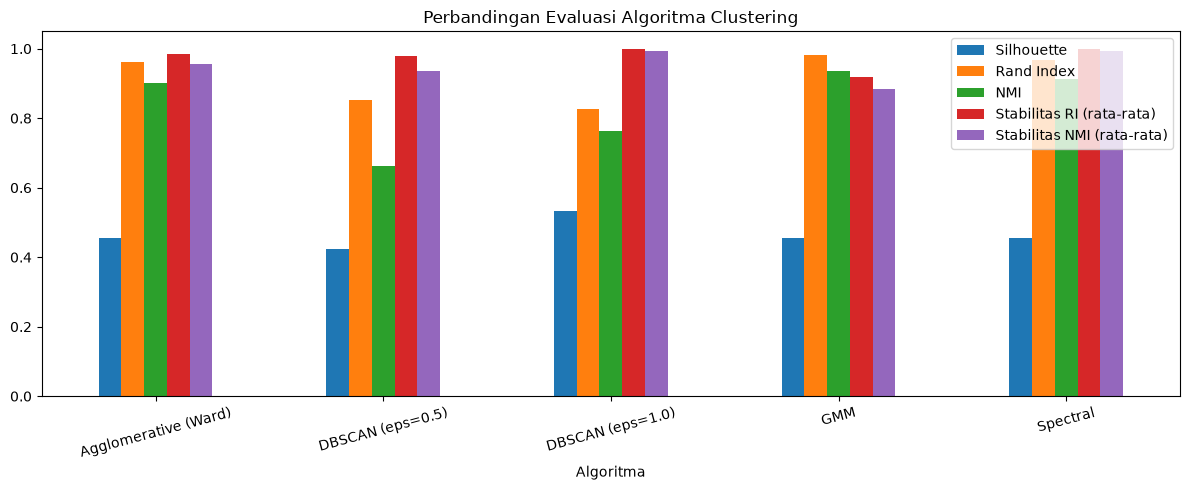

Terbaik berdasarkan Silhouette: DBSCAN (eps=1.0) (0.5336)
Terbaik berdasarkan Rand Index: GMM (0.9817)
Terbaik berdasarkan NMI: GMM (0.9349)
Terbaik berdasarkan Stabilitas NMI (rata-rata): DBSCAN (eps=1.0) (0.9943)


In [24]:
summary[['Silhouette', 'Rand Index', 'NMI', 'Stabilitas RI (rata-rata)', 'Stabilitas NMI (rata-rata)']].plot.bar(figsize=(12, 5))
plt.title('Perbandingan Evaluasi Algoritma Clustering')
plt.xticks(rotation=15)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

for col in ['Silhouette', 'Rand Index', 'NMI', 'Stabilitas NMI (rata-rata)']:
    print(f'Terbaik berdasarkan {col}: {summary[col].idxmax()} ({summary[col].max():.4f})')